<a href="https://colab.research.google.com/github/Chidera-Obiajunwa/sickle-cell-trial-landscape/blob/main/sickle_cell_trials.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sickle cell disease & beta-thalassaemia: clinical trial landscape

**Questions:** Where is research on these two blood disorders happening, who funds it,
which treatments are being tested, and where are the gaps?

**Data:** ClinicalTrials.gov public API v2 (free, no login).

**Workflow (ETL):**
1. **Extract**: download every trial record for both diseases.
2. **Transform**: pick out the fields we need and clean them into linked tables.
3. **Analyse**: count, compare and chart.

**Tip:** to rebuild everything from scratch, use **Runtime → Run all**. Cells must run top to bottom,
because each one uses results from the cells above it.

## 1. Setup: load the tools

In [1]:
# requests: downloads data from the internet
import requests

# pandas: works with tables ("pd" for short)
import pandas as pd

# re: searches text for patterns (used to classify treatments)
import re

# matplotlib: makes charts ("plt" for short)
import matplotlib.pyplot as plt

# MaxNLocator: lets us force whole-number tick marks on chart axes
from matplotlib.ticker import MaxNLocator

## 2. Download the trials (Extract)

The API returns at most 1,000 trials per request. Each reply includes a `nextPageToken`
(a bookmark). We keep asking for the next page until there's no bookmark left: **pagination**.

We wrap this in a **function** so the same code can fetch any disease without copying it.

In [2]:
# "def" defines a reusable function; "condition" is its INPUT (the disease to search for)
def fetch_trials(condition):
    url = "https://clinicaltrials.gov/api/v2/studies"   # the API's web address
    trials = []          # collects trials from every page
    bookmark = None      # no bookmark before the first request

    while True:          # keep repeating until we "break"
        # What we ask for: the disease and 1,000 trials per page (the maximum)
        settings = {"query.cond": condition, "pageSize": 1000}
        if bookmark:     # from page 2 onwards, ask for the NEXT page
            settings["pageToken"] = bookmark

        # Send the request; .json() turns the reply into Python lists/dictionaries
        data = requests.get(url, params=settings).json()

        # .extend adds all of this page's trials to our list
        trials.extend(data["studies"])

        # Bookmark for the next page (None means this was the last page)
        bookmark = data.get("nextPageToken")
        if bookmark is None:
            break        # no more pages, so leave the loop

    print(condition, "->", len(trials), "trials")
    return trials        # hand the finished list back


# Use the function once per disease.
# American spelling "thalassemia": ClinicalTrials.gov is a US registry
scd_trials = fetch_trials("sickle cell disease")
thal_trials = fetch_trials("beta thalassemia")

sickle cell disease -> 1221 trials
beta thalassemia -> 365 trials


## 3. Combine and remove duplicates

Some trials (e.g. stem cell transplants) enrol patients with **either** disease, so they appear
in both downloads. We keep one copy of each, using the trial ID (`nctId`) as the key.

**Check:** sickle cell + thalassaemia − overlap = combined total (the Venn diagram rule).

In [3]:
# A dictionary can't hold the same key twice, so storing each trial under its ID
# automatically keeps ONE copy of any trial found by both searches
combined = {}
for trial in scd_trials + thal_trials:          # + joins the two lists
    nct = trial["protocolSection"]["identificationModule"]["nctId"]
    combined[nct] = trial

# Turn the dictionary's values back into a plain list
all_trials = list(combined.values())

# Sets of IDs for each disease; {... for ...} builds a set in one line
scd_ids = {t["protocolSection"]["identificationModule"]["nctId"] for t in scd_trials}
thal_ids = {t["protocolSection"]["identificationModule"]["nctId"] for t in thal_trials}

# & = items in BOTH sets (the overlap)
overlap = scd_ids & thal_ids

print("Sickle cell:", len(scd_ids))
print("Beta-thalassaemia:", len(thal_ids))
print("In both:", len(overlap))
print("Unique trials combined:", len(all_trials))
print("Check:", len(scd_ids) + len(thal_ids) - len(overlap) == len(all_trials))

Sickle cell: 1221
Beta-thalassaemia: 365
In both: 83
Unique trials combined: 1503
Check: True


## 4. Look inside one trial

Each trial is nested data: dictionaries inside dictionaries, like folders inside folders.
Each `["..."]` opens one folder.

In [4]:
first = all_trials[0]                 # [0] = the first item (Python counts from 0)

# protocolSection -> identificationModule -> briefTitle
print(first["protocolSection"]["identificationModule"]["briefTitle"])

# .get() returns None instead of crashing if a field is missing
print(first["protocolSection"]["designModule"].get("phases"))

Effect of Virtual Reality on Pain and Function in Children With Sickle Cell Disease: A Randomized Controlled Trial
['NA']


## 5. Main table: one row per trial (Transform)

Like a systematic-review extraction sheet: for each trial, copy out a few facts.

**Cleaning decisions**
- `phases` is a list (`['PHASE2', 'PHASE3']`), so it's joined into one label `PHASE2/PHASE3`.
- Observational studies have **no** phase field, so they're labelled `No phase`.
- `NA` = an interventional study of something that isn't a drug (a device, behavioural programme etc.).
- `.get(..., {})` everywhere means one odd record with a missing section can't crash the whole run.

In [5]:
rows = []                                       # empty list; each trial becomes one row

for trial in all_trials:
    p = trial["protocolSection"]                # shortcut
    design = p.get("designModule", {})          # {} if missing

    # Clean the phase: missing -> "No phase"; list -> "PHASE2/PHASE3"
    phases = design.get("phases")
    phase = "No phase" if phases is None else "/".join(phases)

    # Age groups allowed, e.g. ["CHILD", "ADULT"]; [] if missing
    ages = p.get("eligibilityModule", {}).get("stdAges", [])

    # Lead sponsor; {} if missing
    sponsor = p.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {})

    # Start date looks like "2023-09-01" or "2023-09"; first 4 characters = year
    date = p.get("statusModule", {}).get("startDateStruct", {}).get("date", "")
    start_year = int(date[:4]) if date[:4].isdigit() else None

    rows.append({
        "nct_id": p["identificationModule"]["nctId"],   # unique trial ID
        "study_type": design.get("studyType"),           # INTERVENTIONAL / OBSERVATIONAL / ...
        "phase": phase,                                  # cleaned phase label
        "includes_children": "CHILD" in ages,            # True/False
        "sponsor_class": sponsor.get("class"),           # INDUSTRY / OTHER / NIH / ...
        "start_year": start_year,                        # e.g. 2023
    })

df = pd.DataFrame(rows)                         # list of rows -> table

# --- Disease label ---
in_scd = df["nct_id"].isin(scd_ids)             # True if found by the sickle cell search
in_thal = df["nct_id"].isin(thal_ids)           # True if found by the thalassaemia search
df["disease"] = "Sickle cell"                   # default label...
# .loc[rows, column] = value changes only the chosen rows; ~ means NOT
df.loc[in_thal & ~in_scd, "disease"] = "Beta-thalassaemia"
df.loc[in_thal & in_scd, "disease"] = "Both"

print(len(df), "trials")
df.head()                                       # first 5 rows

1503 trials


,nct_id,study_type,phase,includes_children,sponsor_class,start_year,disease
0,NCT05952817,INTERVENTIONAL,NA,True,OTHER_GOV,2023.0,Sickle cell
1,NCT00004412,INTERVENTIONAL,PHASE2,True,OTHER,1997.0,Both
2,NCT04793854,OBSERVATIONAL,No phase,True,OTHER,2018.0,Sickle cell
3,NCT04330183,INTERVENTIONAL,PHASE4,False,OTHER,2020.0,Sickle cell
4,NCT04076683,INTERVENTIONAL,NA,False,OTHER,2022.0,Sickle cell


## 6. First counts

In [6]:
# value_counts() counts how often each value appears; "\n" prints a blank line
print(df["disease"].value_counts(), "\n")
print(df["study_type"].value_counts(), "\n")
print(df["sponsor_class"].value_counts(), "\n")
print(df["includes_children"].value_counts())

disease
Sickle cell          1138
Beta-thalassaemia     282
Both                   83
Name: count, dtype: int64 

study_type
INTERVENTIONAL     1078
OBSERVATIONAL       419
EXPANDED_ACCESS       6
Name: count, dtype: int64 

sponsor_class
OTHER        1052
INDUSTRY      324
NIH           100
OTHER_GOV      19
NETWORK         8
Name: count, dtype: int64 

includes_children
True     980
False    523
Name: count, dtype: int64


**Lesson:** with only 10 trials, industry sponsorship looked like 0%. With the full data it's about 1 in 5.
A small sample can mislead.

## 7. Country table: one row per trial + country

One trial can run in many countries, so countries can't fit in one cell. We make a **second table**
(one row per trial-country pair), linked to the main table by `nct_id`: a **one-to-many** relationship.

In [7]:
country_rows = []

for trial in all_trials:                        # OUTER loop: each trial
    p = trial["protocolSection"]
    nct = p["identificationModule"]["nctId"]
    locations = p.get("contactsLocationsModule", {}).get("locations", [])

    countries = set()                           # a set ignores duplicates
    for loc in locations:                       # INNER loop: each site of this trial
        country = loc.get("country")
        if country:                             # skip blanks
            countries.add(country)              # 40 US hospitals -> "United States" once

    for country in countries:                   # one row per unique country
        country_rows.append({"nct_id": nct, "country": country})

countries_df = pd.DataFrame(country_rows)

print(len(countries_df), "trial-country pairs")
countries_df["country"].value_counts().head(15)  # top 15 countries

2231 trial-country pairs


,count
country,
United States,824
France,159
United Kingdom,102
Italy,99
Egypt,75
Canada,70
China,59
Lebanon,59
Turkey (Türkiye),57


## 8. Link the tables: which trials have a site in sub-Saharan Africa?

1. Find trial IDs with any sub-Saharan African site (from `countries_df`).
2. Add a True/False column to `df`.
3. The mean of True/False = the proportion that are True.

In [8]:
# Some countries appear twice with different spellings (registries aren't consistent);
# extra names that never appear do no harm
africa = ["Nigeria", "Ghana", "Kenya", "Uganda", "Tanzania", "Tanzania, United Republic of",
          "Congo, The Democratic Republic of the", "Democratic Republic of the Congo", "Congo",
          "Cameroon", "Benin", "Burkina Faso", "Mali", "Senegal", "Côte D'Ivoire", "Ivory Coast",
          "Angola", "Zambia", "Malawi", "South Africa", "Niger", "Togo", "Gabon", "Sudan",
          "Ethiopia", "Mozambique", "Rwanda", "Guinea", "Sierra Leone", "Liberia",
          "Zimbabwe", "Madagascar", "Chad"]

# .isin() -> True/False per row; [ ] keeps the True rows; .unique() drops repeated IDs
africa_ids = countries_df[countries_df["country"].isin(africa)]["nct_id"].unique()

# New True/False column in the main table
df["has_africa_site"] = df["nct_id"].isin(africa_ids)

print("Trials with a sub-Saharan African site:", len(africa_ids),
      f"({df['has_africa_site'].mean() * 100:.1f}%)\n")

# By sponsor type: sum = trials with an African site; count = all trials; ALWAYS show both
by_sponsor = df.groupby("sponsor_class")["has_africa_site"].agg(["sum", "count"])
by_sponsor["percent"] = (by_sponsor["sum"] / by_sponsor["count"] * 100).round(1)
by_sponsor

Trials with a sub-Saharan African site: 94 (6.3%)



,sum,count,percent
sponsor_class,,,
INDUSTRY,34,324,10.5
NETWORK,0,8,0.0
NIH,3,100,3.0
OTHER,55,1052,5.2
OTHER_GOV,2,19,10.5


**Findings (sickle cell):** under 8% of studies have any sub-Saharan African site, though the region
carries most of the global burden. Industry trials are more than twice as likely as academic ones
to include Africa (about 14% vs 6%), probably because large multinational Phase 3 trials recruit widely.
This is an *association*, not a cause.

**Caveats:** many African and Indian trials are registered elsewhere (PACTR, CTRI), so the gap may be overstated.
Groups with very few trials (e.g. 2 of 15) are too small to compare.

## 9. Compare the two diseases

In [9]:
# .agg(new_column=(source_column, how)) builds several summaries at once
# lambda s: ... is a tiny unnamed function; s = that group's column
summary = df.groupby("disease").agg(
    trials=("nct_id", "count"),
    pct_industry=("sponsor_class", lambda s: round((s == "INDUSTRY").mean() * 100, 1)),
    pct_africa=("has_africa_site", lambda s: round(s.mean() * 100, 1)),
)
summary

,trials,pct_industry,pct_africa
disease,,,
Beta-thalassaemia,282,30.9,0.4
Both,83,25.3,3.6
Sickle cell,1138,19.0,7.9


**Finding:** about 31% of thalassaemia-only trials are industry-sponsored vs 19% for sickle cell.
*Hypothesis:* thalassaemia patients are concentrated in higher-income health systems (Mediterranean, Gulf),
and lifelong transfusion and chelation make a clear, ongoing market.

**Trap avoided:** thalassaemia's near-zero African share isn't a gap. The disease is mainly found in the Mediterranean,
the Middle East and South Asia. The "African site" measure only makes sense for sickle cell.

## 10. Chart: where trials are run

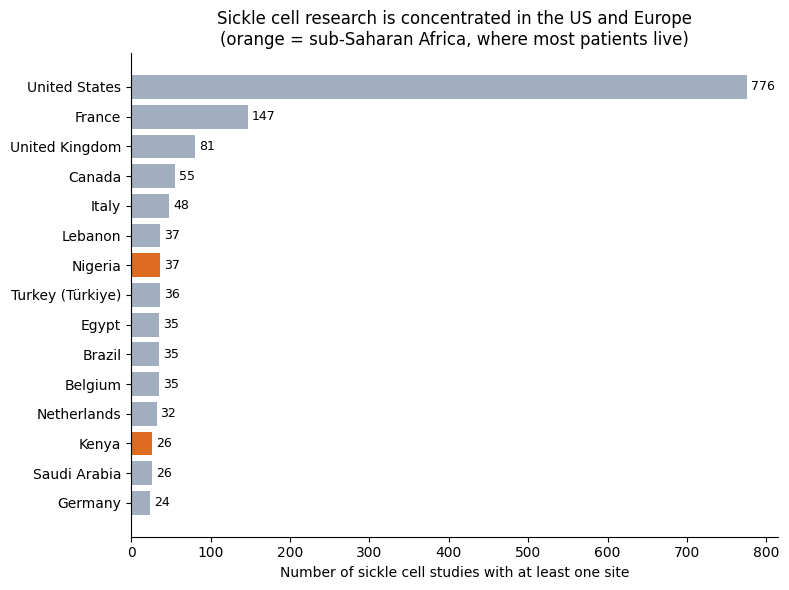

In [10]:
# Top 15 countries for SICKLE CELL studies (the disease where Africa matters)
scd_country = countries_df[countries_df["nct_id"].isin(scd_ids)]
top = scd_country["country"].value_counts().head(15)

top = top.iloc[::-1]          # reverse so the biggest bar is at the TOP

# Orange if African, grey otherwise (a one-line loop: "list comprehension")
colours = ["#dd6b20" if c in africa else "#a0aec0" for c in top.index]

fig, ax = plt.subplots(figsize=(8, 6))          # blank figure (width, height in inches)
ax.barh(top.index, top.values, color=colours)   # horizontal bars

# Write each number at the end of its bar; enumerate gives position + value
for i, value in enumerate(top.values):
    ax.text(value + 5, i, str(value), va="center", fontsize=9)

ax.set_xlabel("Number of sickle cell studies with at least one site")
# A title that states the FINDING, not just the topic
ax.set_title("Sickle cell research is concentrated in the US and Europe\n"
             "(orange = sub-Saharan Africa, where most patients live)")
ax.spines[["top", "right"]].set_visible(False)  # remove top/right borders
plt.tight_layout()                              # stop labels being cut off
plt.savefig("countries_chart.png", dpi=150)     # save as an image file
plt.show()

**Finding:** *Sub-Saharan Africa is under-represented in sickle cell research: only two African countries
appear in the top 15, and fewer than 8% of studies have any site there, despite the region carrying most of
the global disease burden.*

## 11. Chart: sponsor type vs African sites

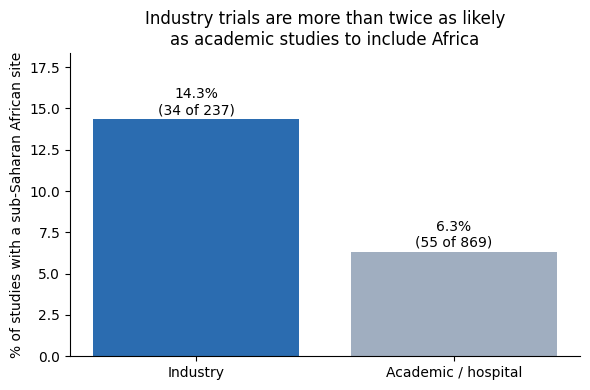

In [11]:
# Only the two large groups; tiny groups are unreliable
s = df[df["disease"] != "Beta-thalassaemia"]          # Africa measure only makes sense for sickle cell
s = s.groupby("sponsor_class")["has_africa_site"].agg(["sum", "count"]).loc[["INDUSTRY", "OTHER"]]
s["percent"] = s["sum"] / s["count"] * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Industry", "Academic / hospital"], s["percent"], color=["#2b6cb0", "#a0aec0"])

# Label each bar with % AND raw count; zip pairs each bar with its row
for bar, (_, row) in zip(bars, s.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2,      # centre of the bar
            bar.get_height() + 0.3,                  # just above it
            f"{row['percent']:.1f}%\n({int(row['sum'])} of {int(row['count'])})",  # f-string
            ha="center", fontsize=10)

ax.set_ylabel("% of studies with a sub-Saharan African site")
ax.set_title("Industry trials are more than twice as likely\nas academic studies to include Africa")
ax.set_ylim(0, s["percent"].max() + 4)              # room for the labels
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("sponsor_africa_chart.png", dpi=150)
plt.show()

## 12. Classify treatments (keyword rules)

Each trial names its treatments in free text ("exa-cel", "CTX001", "CRISPR-edited cells"...).
We sort them into categories with **keyword rules**, refined over three rounds by reading what was left unclassified.

**Regex tips:** `|` = OR · `-?` = optional hyphen · `\b` = word boundary (`\bapp\b` won't match "approach").
**Order matters:** the first matching rule wins, so specific rules come before broad ones.

In [12]:
rules = [
    # Not real treatments: labelled first so they never land in a drug category
    ("Placebo / comparator",  r"placebo|sham|standard of care|usual care"),
    ("Not a treatment",       r"blood sampl|blood draw|blood collection|no intervention|observational|ultrasound"),

    # Gene therapies
    ("Gene editing",          r"crispr|cas9|exa-?cel|exagamglogene|ctx001|base edit|bcl11a"),
    ("Gene addition (viral)", r"lentivir|lovo-?cel|lovotibeglogene|beti-?cel|betibeglogene|lentiglobin|gene therap"),

    # Transplant / gene therapy SUPPORT: mobilise stem cells -> condition marrow -> suppress immunity
    ("Stem cell mobilisation", r"plerixafor|filgrastim|g-csf"),
    ("Conditioning / immunosuppression",
        r"busulfan|melphalan|thiotepa|fludarabine|cyclophosphamide|total body irradiation|"
        r"alemtuzumab|thymoglobulin|antithymocyte|\batg\b|sirolimus|tacrolimus|"
        r"mycophenolate|methotrexate|abatacept|rituximab"),

    # Main treatment types
    ("Stem cell transplant",  r"transplant|hsct|stem cell|bone marrow|cord blood|haploidentical"),
    ("Hydroxyurea",           r"hydroxyurea|hydroxycarbamide"),
    ("Iron chelation",        r"deferasirox|deferoxamine|deferiprone|chelat"),
    ("Transfusion",           r"transfusion|red blood cell"),
    # Includes company CODE names: gbt440 = voxelotor, gbt021601 = osivelotor
    ("Newer drugs",           r"luspatercept|mitapivat|etavopivat|voxelotor|crizanlizumab|glutamine|"
                              r"inclacumab|osivelotor|gbt440|gbt021601|imr-?687|hqk-?1001|aes-?103"),
    ("Repurposed drugs",      r"sildenafil|losartan|amlodipine|metformin|prasugrel"),
    ("Supplements / nutrition", r"vitamin|spirulina|citrulline"),
    ("Pain management",       r"opioid|morphine|ketamine|analges|lidocaine"),
    ("Device / digital / behavioural",
        r"virtual reality|\bapp\b|mobile|education|behavio|counsel|program|music"),
]

def classify(text):
    """Return the first category whose pattern appears in the text, else 'Other'."""
    text = text.lower()                      # lowercase so "CRISPR" matches "crispr"
    for category, pattern in rules:          # try rules in order
        if re.search(pattern, text):         # pattern found anywhere in the text?
            return category                  # first match wins
    return "Other"

# One row per trial + treatment (another one-to-many table)
treatment_rows = []
for trial in all_trials:
    p = trial["protocolSection"]
    nct = p["identificationModule"]["nctId"]
    for iv in p.get("armsInterventionsModule", {}).get("interventions", []):
        name = iv.get("name", "")
        category = classify(name)                             # 1) NAME first (most reliable)
        if category == "Other":
            category = classify(iv.get("description", ""))    # 2) description as a fallback
        treatment_rows.append({"nct_id": nct, "treatment": name, "category": category})

treatments_df = pd.DataFrame(treatment_rows)

print(treatments_df["category"].value_counts(), "\n")
pct_other = (treatments_df["category"] == "Other").mean() * 100
print("Still unclassified:", round(pct_other, 1), "%")

category
Other                               856
Conditioning / immunosuppression    270
Placebo / comparator                232
Device / digital / behavioural      150
Hydroxyurea                         120
Newer drugs                         106
Stem cell transplant                 98
Not a treatment                      84
Iron chelation                       78
Pain management                      63
Transfusion                          61
Supplements / nutrition              36
Gene addition (viral)                28
Repurposed drugs                     27
Gene editing                         25
Stem cell mobilisation               24
Name: count, dtype: int64 

Still unclassified: 37.9 %


In [13]:
# What the rules still miss. Read this to decide whether another rule is worth adding
treatments_df[treatments_df["category"] == "Other"]["treatment"].value_counts().head(25)

,count
treatment,
L-NMMA,4
Nitric Oxide,4
Arginine,3
Acetylcholine,3
SP-420,3
Thalidomide,3
Ibuprofen,3
OTQ923,3
Bortezomib,3


**Method note:** interventions were classified with keyword rules refined over three rounds by
reviewing unclassified items (65% → 44% → 38% unclassified). The remainder is a long tail of drugs
appearing fewer than 7 times each, so further rules give diminishing returns.
Rules check the intervention name first, and the description only as a fallback.

## 13. Chart: trial starts per year by treatment type

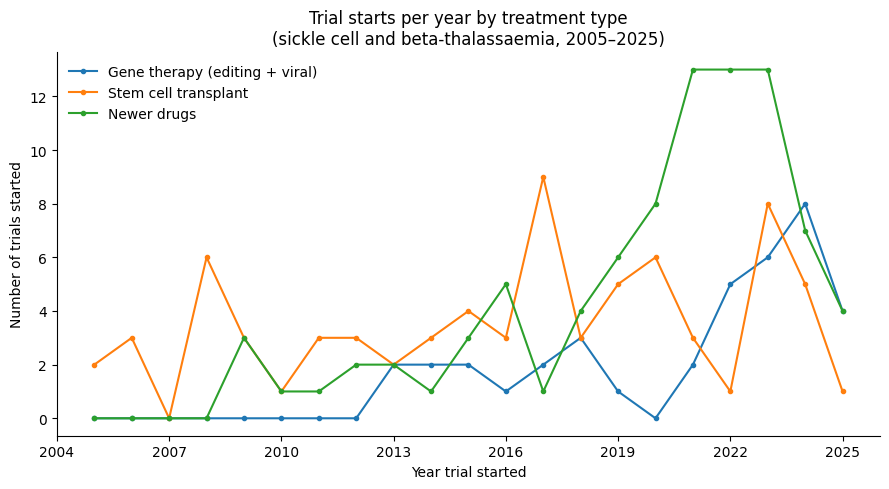

,Gene therapy (editing + viral),Stem cell transplant,Newer drugs
start_year,,,
2016,1,3,5
2017,2,9,1
2018,3,3,4
2019,1,5,6
2020,0,6,8
2021,2,3,13
2022,5,1,13
2023,6,8,13
2024,8,5,7


In [14]:
# Flag trials that include at least one treatment in each headline group
groups = {
    "Gene therapy (editing + viral)": ["Gene editing", "Gene addition (viral)"],
    "Stem cell transplant":           ["Stem cell transplant"],
    "Newer drugs":                    ["Newer drugs"],
}
for label, cats in groups.items():           # .items() gives name + value pairs
    ids = treatments_df[treatments_df["category"].isin(cats)]["nct_id"].unique()
    df[label] = df["nct_id"].isin(ids)       # True/False column per group

# 2005-2025 only: 2026 is unfinished and would look like a false drop
recent = df[(df["start_year"] >= 2005) & (df["start_year"] <= 2025)]

# .sum() of True/False columns per year = number of trials started
per_year = recent.groupby("start_year")[list(groups.keys())].sum()
per_year.index = per_year.index.astype(int)  # 2016.0 -> 2016

fig, ax = plt.subplots(figsize=(9, 5))
for label in groups:
    ax.plot(per_year.index, per_year[label], marker="o", markersize=3, label=label)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole years only on the axis
ax.set_xlabel("Year trial started")
ax.set_ylabel("Number of trials started")
ax.set_title("Trial starts per year by treatment type\n(sickle cell and beta-thalassaemia, 2005–2025)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("treatment_trends_chart.png", dpi=150)
plt.show()

per_year.tail(10)

**Findings:**
- **Gene therapy trials are rising:** none before 2013, then a steady climb since 2020, peaking in 2024,
  in line with the first approvals.
- **Newer drug trials plateaued in 2021–23, then fell in 2024.** *Hypothesis:* the 2024 withdrawal of voxelotor
  may have cooled investment. This needs checking.
- **Transplant trials** are steady but bumpy, with no clear trend.

**Cautions:** counts are single digits, so describe trends rather than exact jumps. Recent years are
under-counted because trials are often registered after they start (**reporting lag**), so the 2025 dip may not be real.

## 14. Summary of findings

1. Sub-Saharan Africa hosts fewer than 8% of sickle cell studies despite carrying most of the global burden; India is absent from the top 15 countries.
2. About 4 in 5 sickle cell studies are run by academic or government sponsors, not industry.
3. Industry trials are more than twice as likely as academic ones to include an African site (association, likely driven by large multinational trials).
4. Thalassaemia attracts proportionally more industry sponsorship (about 31% vs 19%).
5. Gene therapy trial activity has grown steadily since 2020.

**Limitations:** ClinicalTrials.gov only (regional registries missed); keyword classification leaves about 38% of interventions unclassified; reporting lag in recent years.

##15. SQL : reproducing the findings

In [15]:
import sqlite3

conn = sqlite3.connect("trials.db")
df.to_sql("trials", conn, index=False, if_exists="replace")

1503

In [16]:
pd.read_sql("SELECT COUNT(*) FROM trials", conn)

,COUNT(*)
0,1503


In [17]:
pd.read_sql("SELECT COUNT(*) FROM trials WHERE sponsor_class = 'INDUSTRY'",conn)

,COUNT(*)
0,324


In [18]:
pd.read_sql("SELECT COUNT(*) FROM trials WHERE sponsor_class = 'OTHER'",conn)

,COUNT(*)
0,1052


In [21]:
pd.read_sql("SELECT COUNT (*) FROM trials WHERE start_year >= 2020",conn)

,COUNT (*)
0,609


In [22]:
pd.read_sql("""
SELECT sponsor_class, COUNT (*) AS trials
FROM trials
GROUP BY sponsor_class
ORDER BY trials DESC
""",conn)

,sponsor_class,trials
0,OTHER,1052
1,INDUSTRY,324
2,NIH,100
3,OTHER_GOV,19
4,NETWORK,8


In [23]:
pd.read_sql("""
SELECT phase, COUNT (*) AS trials
FROM trials
GROUP BY phase
ORDER BY trials DESC
""",conn)

,phase,trials
0,No phase,425
1,NA,351
2,PHASE2,259
3,PHASE3,125
4,PHASE1,124
5,PHASE1/PHASE2,97
6,PHASE4,70
7,PHASE2/PHASE3,30
8,EARLY_PHASE1,22


In [25]:
countries_df.to_sql("trial_countries", conn, index=False, if_exists="replace")

2231

In [26]:
pd.read_sql("""
SELECT country, COUNT (*) AS trials
FROM trial_countries
GROUP BY country
ORDER BY trials DESC
LIMIT 10
""", conn)

,country,trials
0,United States,824
1,France,159
2,United Kingdom,102
3,Italy,99
4,Egypt,75
5,Canada,70
6,Lebanon,59
7,China,59
8,Turkey (Türkiye),57
9,Greece,46


In [27]:
pd.read_sql("""
SELECT c.country, COUNT (*) As trials
FROM trial_countries c
JOIN trials t ON t.nct_id = c.nct_id
WHERE t.disease != 'Beta-thalassaemia'
GROUP BY c.country
ORDER BY trials DESC
LIMIT 10
""",conn)

,country,trials
0,United States,776
1,France,147
2,United Kingdom,81
3,Canada,55
4,Italy,48
5,Nigeria,37
6,Lebanon,37
7,Turkey (Türkiye),36
8,Egypt,35
9,Brazil,35


In [29]:
pd.read_sql("""
SELECT COUNT(*) AS trials,
      SUM(has_africa_site) As with_africa,
      ROUND(100.0 * AVG(has_africa_site ), 1) AS pct
FROM trials
WHERE disease != 'Beta-thalassaemia'
""",conn)

,trials,with_africa,pct
0,1221,93,7.6


In [30]:
pd.read_sql("""
SELECT sponsor_class, COUNT (*) AS trials,
      SUM(has_africa_site) As with_africa,
      ROUND(100.0 * AVG(has_africa_site ), 1) AS pct
FROM trials
WHERE disease != 'Beta-thalassaemia'
GROUP BY sponsor_class
""",conn)

,sponsor_class,trials,with_africa,pct
0,INDUSTRY,237,34,14.3
1,NETWORK,7,0,0.0
2,NIH,93,2,2.2
3,OTHER,869,55,6.3
4,OTHER_GOV,15,2,13.3
